# Week 4: Decision Tree Classification

# First time here?



1.   Copy this file to your Google Drive so you can edit it: **File->Save a copy in Drive** (requires a personal Google account)
2.   Done? Consider giving your copy a better name (e.g., including your name and/or student ID) - just click on the filename in the top left and edit it.
3.   (Want to re-open your copy in future? Go: **File->Open notebook** and select the Google Drive tab)
4.   (Want to find your file on your Google Drive? Google puts Colab files in a folder called "Colab Notebooks")

# Our implementations (DT)

In this notebook we're going to focus on understanding a very simple Python implementation of a Decision Tree (DT).

It should be useful for checking your understanding from your research this week, and it may also be useful to return to and extend in future.

## `MyDecisionTreeClassifier`

Below is a really simple NumPy implementation of a Decision Tree (DT) classifier. We'll take some time to look at it in detail in a moment, but for now let's just run it and see how it performs.

Click the play button on the code cell to define the class, and then scroll down to the next text cell and keep reading:

In [6]:
import numpy as np

# A class to represent a single node in our tree

class MyDtNode:
  def __init__(self, examples, labels):
    # Set up information about this node
    self.examples = examples
    self.labels = labels
    self.N = examples.shape[0]
    self.left = None
    self.right = None
    self.gdi = np.nan
    self.feature = np.nan
    self.threshold = np.nan

    # use np.unique to count how many times each label appeared in the predictions
    unique_labels, counts = np.unique(labels, return_counts=True)
    # find the one that appeared most (just the lowest index/first alphabetically if there's a tie)
    max_count_index = np.argmax(counts)
    # take the associated prediction
    self.prediction = unique_labels[max_count_index]

# A decision tree class

class MyDecisionTreeClassifier:


  def __init__(self, min_parent_size=5):
  # store the minimum parent size
    self.min_parent_size = min_parent_size


  # The method we call to fit the model to training data
  def fit(self, train_examples, train_labels):
    # store the training data
    self.train_examples = train_examples
    self.train_labels = train_labels
    # take a record of the unique labels in the problem
    self.unique_labels = np.unique(train_labels)
    # and how many example/label pairs are in this node
    self.N = train_examples.shape[0]

    # create the root node, and start off the splitting/tree building process
    self.root = MyDtNode(train_examples, train_labels)
    self.try_split(self.root)

  # Try splitting a node
  def try_split(self, node):

    # Just an example of enforcing minimum parent size (hard-coded)
    if node.examples.shape[0] < self.min_parent_size:
      # at this point, we could delete the examples/labels data from the parent if we wanted to keep the model small...
      return

    # set this node's gdi
    node.gdi = self.weighted_gdi(node.labels)

    if node.gdi == 0:
      # already a pure node - no improvement possible
      # at this point, we could delete the examples/labels data from the parent if we wanted to keep the model small...
      return

    best_gdi = np.inf
    best_feature = np.nan
    best_example = np.nan

    #
    for i in range(node.examples.shape[1]):
      #
      sorted_indices = np.argsort(node.examples[:, i])
      #
      for j in range(node.examples.shape[0]-1):
        left_labels = node.labels[sorted_indices[:j+1]]
        right_labels = node.labels[sorted_indices[j+1:]]
        # how were the combined weighted GDI scores, versus what we've already seen
        this_gdi = self.weighted_gdi(left_labels) + self.weighted_gdi(right_labels)
        # only update if there was an improvement (we don't handle ties)
        if this_gdi < best_gdi:
          best_gdi = this_gdi
          best_feature = i
          best_example = j

    if (node.gdi - best_gdi) <= 0:
      # no split that improves diversity is available
      # at this point, we could delete the examples/labels data from the parent if we wanted to keep the model small...
      return

    # Make the winning split
    # sort on the winning feature
    sorted_indices = np.argsort(node.examples[:, best_feature])
    left_labels = node.labels[sorted_indices[:best_example+1]]
    right_labels = node.labels[sorted_indices[best_example+1:]]
    left_examples = node.examples[sorted_indices[:best_example+1], :]
    right_examples = node.examples[sorted_indices[best_example+1:], :]

    # set up the details for this node (predictive feature/threshold it asks about)
    node.feature = best_feature
    node.threshold = (node.examples[sorted_indices[best_example], best_feature] + node.examples[sorted_indices[best_example+1], best_feature]) / 2

    # make the two children
    node.left = MyDtNode(left_examples, left_labels)
    node.right = MyDtNode(right_examples, right_labels)

    # at this point, we could delete the examples/labels data from the parent if we wanted to keep the model small...

    # and now try splitting the children
    self.try_split(node.left)
    self.try_split(node.right)

  # A method to compute weighted GDI
  def weighted_gdi(self, labels):
    # weighting based on likelihood we get into this node - what fraction of the training example/labels got into it
    weight = float(labels.size) / float(self.N)

    gdi = 0
    # add up the (squared) fractions of each label present in this node
    for this_label in self.unique_labels:
      this_frac = float(sum(labels == this_label)) / float(labels.size)
      gdi += this_frac * this_frac

    # subtract from 1 (so that higher scores correspond to higher diversity)
    return weight * (1 - gdi)


  # The method we call to generate predictions for a batch of testing examples (exactly the same as last time)
  def predict(self, test_examples):

    # how many test examples are there
    n_test_examples = test_examples.shape[0]

    # make numpy array the right size to store our predicted labels
    predicted_labels = np.empty(n_test_examples, dtype=self.train_labels.dtype)

    # loop over all the testing examples that were passed to us
    for i in range(n_test_examples):

        # For this one testing example...
        this_example = test_examples[i,:]

        # generate a prediction and store it
        predicted_labels[i] = self.predict_one(this_example)

    # return all the predictions
    return predicted_labels

  # A method to generate a prediction for a single example
  def predict_one(self, this_example):

    node = self.root

    #
    while (node.left is not None):
      #
      this_feature = node.feature
      this_threshold = node.threshold
      #
      if this_example[this_feature] <= this_threshold:
        node = node.left
      else:
        node = node.right

    #
    return node.prediction

## Basic supervised learning recipe

The code below shows our basic supervised learning recipe again. We're using it to train and evaluate on the iris.csv dataset again, but this time we're using the basic DT implementation we defined above.

*   How accurate is the model? ** 93.3 %**

Accuracy: 0.9666666666666667 (or 96.7 %)

Confusion Matrix:
[[17  0  0]
 [ 0 22  0]
 [ 0  2 19]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        17
  versicolor       0.92      1.00      0.96        22
   virginica       1.00      0.90      0.95        21

    accuracy                           0.97        60
   macro avg       0.97      0.97      0.97        60
weighted avg       0.97      0.97      0.97        60



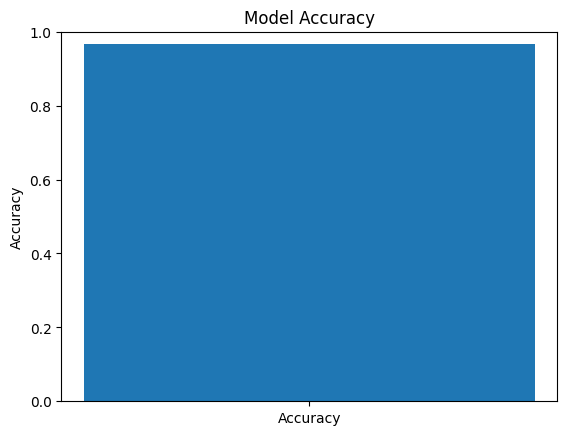

In [12]:
# Import the packages we use
import pandas as pd
import numpy as np

from sklearn.metrics import confusion_matrix, classification_report

# Load all the observations from file
observations = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/iris.csv')

# Set the name of the target feature
target_feature = 'species'

# Shuffle all the observations
observations_shuffled = observations.sample(frac=1, random_state=99)

# Set the fraction of observations we will use for testing
testing_fraction = 0.4
split_index = int(observations_shuffled.shape[0] * testing_fraction)

# Split into testing observations and training observations ("horizontal split")
observations_test = observations_shuffled.iloc[:split_index]
observations_train = observations_shuffled.iloc[split_index:]

# Split into testing examples and testing labels ("vertical split")
test_examples = observations_test.drop(columns=target_feature).to_numpy()
test_labels = observations_test[target_feature].to_numpy()

# Split into training examples and training labels ("vertical split")
train_examples = observations_train.drop(columns=target_feature).to_numpy()
train_labels = observations_train[target_feature].to_numpy()

# Create a DT classification model
model = MyDecisionTreeClassifier()

# Call the model's fitting/training algorithm, passing in our training examples and training labels
model.fit(train_examples, train_labels)

# Use the trained model to generate predictions based on our testing examples
predictions = model.predict(test_examples)

# Find the total number of model predictions that matched with their corresponding testing labels
correct_predictions = sum(predictions == test_labels)
# Calculate the model's accuracy: the fraction of predictions that were correct
accuracy = correct_predictions / len(test_labels)
# Display the accuracy as a single quantitative measure of overall performance
print("Accuracy:", accuracy, "(or", round(accuracy*100, 1), "%)")

#  Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(test_labels, predictions))

#  Classification report
print("\nClassification Report:")
print(classification_report(test_labels, predictions))


import matplotlib.pyplot as plt

# Simple bar chart showing accuracy
plt.bar(["Accuracy"], [accuracy])
plt.ylim(0, 1)  # Accuracy is between 0 and 1
plt.title("Model Accuracy")
plt.ylabel("Accuracy")

plt.show()



# Review

Now take some time to have a careful look through the `MyDecisionTreeClassifier` class. Can you match each of the stages up with your research from this week? It's worth spending time on this task - you want to ensure you understand the model fully:

*    **Add descriptive comments where they are missing in the code**

**Tip**: notice that the basic approach to constructing the tree is just like the one we used in the A&DS module - it is built out of a single, simple `MyDtNode` object, which can store two `MyDtNode` objects as children. Notice also that `try_split()` is a recursive method that ends by calling itself again on any newly created children.

**Tip**: consider adding print statements to `MyDecisionTreeClassifier` to help you understand what's happening. Re-run the code cell that defines the class before re-running the recipe code to see the output. Remember about printing things like `.shape` as well as printing out the raw contents of arrays (which can produce many lines of output).

## Minimum parent size

Minimum parent size is a useful decision tree hyperparameter for controlling tree depth. It says: unless nodes have some minimum amount of training data inside them, don't even consider splitting them. Setting higher values stops branches becoming as deep as they otherwise might do.

Currently, the code applies a hard-coded minimum parent size inside its `try_split()` method. Can you update the class constructor to accept a minimum parent size as an argument called `min_parent_size`, and use it to replace the hard-coded value used in `try_split()`?

*    **Try out your new hyperparameter value in the calling code above - do you see any changes in model accuracy?** Yes, after changing the minimal samples from 10 to 5, the models accuracy increased from 93.3% to 96.7 %

**Tip**: your calling code might change to something like `MyDecisionTreeClassifier(min_parent_size=1)`, for example. Try out a few different values.

**Tip**: you can have a look back at the `MyKNeighboursClassifier` (from a couple of weeks ago) for a reminder of how to handle constructor arguments.


## Next steps

You could, if you wanted to, add more code to this `MyDecisionTreeClassifier` class in order to gain further insight into the workings of the model's `fit()` and `predict()` methods. For example, see how we use the Matplotlib package for visualisation in the second notebook.